In [2]:
from google.colab import files

uploaded = files.upload()

Saving cookie_cats.csv to cookie_cats.csv


In [3]:
import pandas as pd

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

display(df.head())

print("Размер датасета:", df.shape)
print("Столбцы:", df.columns.tolist())

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


Размер датасета: (90189, 5)
Столбцы: ['userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7']


In [4]:
# 1. Проверяем пропуски
print("Пропуски по столбцам:")
print(df.isna().sum())

# 2. Проверяем дубликаты игроков
print("\nДубликаты userid:", df["userid"].duplicated().sum())

# 3. Сравниваем размеры экспериментальных групп
print("\nКоличество игроков в группах:")
print(df["version"].value_counts())

# 4. Смотрим основные характеристики активности
print("\nКоличество игровых раундов:")
display(df["sum_gamerounds"].describe())

# 5. Проверяем значения признаков возвращаемости
print("\nВозвращаемость на следующий день:")
print(df["retention_1"].value_counts())

print("\nВозвращаемость через 7 дней:")
print(df["retention_7"].value_counts())

Пропуски по столбцам:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Дубликаты userid: 0

Количество игроков в группах:
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

Количество игровых раундов:


,sum_gamerounds
count,90189.000000
mean,51.872457
std,195.050858
min,0.000000
25%,5.000000
50%,16.000000
75%,51.000000
max,49854.000000



Возвращаемость на следующий день:
retention_1
False    50036
True     40153
Name: count, dtype: int64

Возвращаемость через 7 дней:
retention_7
False    73408
True     16781
Name: count, dtype: int64


In [6]:
# Сравниваем показатели двух экспериментальных групп
summary = (
    df.groupby("version")
    .agg(
        players=("userid", "nunique"),
        avg_gamerounds=("sum_gamerounds", "mean"),
        median_gamerounds=("sum_gamerounds", "median"),
        retention_1=("retention_1", "mean"),
        retention_7=("retention_7", "mean"),
    )
    .reset_index()
)

# Переводим доли удержания в проценты
summary["retention_1_pct"] = summary["retention_1"] * 100
summary["retention_7_pct"] = summary["retention_7"] * 100

# Выводим показатели в удобном формате
display(
    summary[
        [
            "version",
            "players",
            "avg_gamerounds",
            "median_gamerounds",
            "retention_1_pct",
            "retention_7_pct",
        ]
    ].round(2)
)

,version,players,avg_gamerounds,median_gamerounds,retention_1_pct,retention_7_pct
0,gate_30,44700,52.46,17.0,44.82,19.02
1,gate_40,45489,51.30,16.0,44.23,18.20


In [7]:
import pandas as pd
from scipy.stats import chi2_contingency


def test_retention(column, label):
    # Количество вернувшихся и не вернувшихся игроков
    table = pd.crosstab(df["version"], df[column])

    # Проверяем, отличается ли удержание между группами
    chi2, p_value, dof, expected = chi2_contingency(
        table,
        correction=False
    )

    rates = df.groupby("version")[column].mean() * 100

    difference = rates["gate_30"] - rates["gate_40"]

    print(f"\n{label}")
    print("-" * 40)
    print(f"Удержание gate_30: {rates['gate_30']:.2f}%")
    print(f"Удержание gate_40: {rates['gate_40']:.2f}%")
    print(f"Разница: {difference:+.2f} п. п.")
    print(f"p-value: {p_value:.5f}")

    if p_value < 0.05:
        print("Результат статистически значим при уровне 5%.")
    else:
        print("Статистически значимая разница не обнаружена.")


test_retention("retention_1", "Удержание на следующий день")
test_retention("retention_7", "Удержание через 7 дней")


Удержание на следующий день
----------------------------------------
Удержание gate_30: 44.82%
Удержание gate_40: 44.23%
Разница: +0.59 п. п.
p-value: 0.07441
Статистически значимая разница не обнаружена.

Удержание через 7 дней
----------------------------------------
Удержание gate_30: 19.02%
Удержание gate_40: 18.20%
Разница: +0.82 п. п.
p-value: 0.00155
Результат статистически значим при уровне 5%.


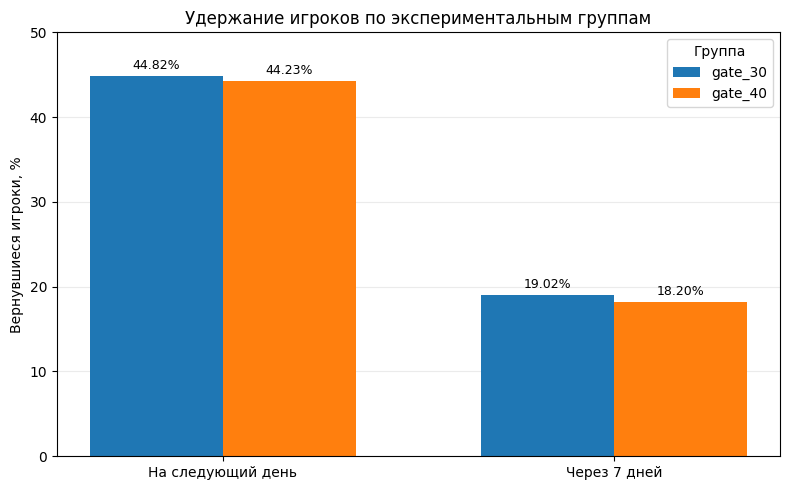

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Данные из нашей сводной таблицы
plot_data = summary.set_index("version").loc[["gate_30", "gate_40"]]

metrics = ["retention_1_pct", "retention_7_pct"]
labels = ["На следующий день", "Через 7 дней"]

x = np.arange(len(metrics))
width = 0.34

fig, ax = plt.subplots(figsize=(8, 5))

bars_30 = ax.bar(
    x - width / 2,
    plot_data[metrics].iloc[0].values,
    width,
    label="gate_30",
)

bars_40 = ax.bar(
    x + width / 2,
    plot_data[metrics].iloc[1].values,
    width,
    label="gate_40",
)

ax.set_title("Удержание игроков по экспериментальным группам")
ax.set_ylabel("Вернувшиеся игроки, %")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 50)
ax.legend(title="Группа")
ax.bar_label(bars_30, fmt="%.2f%%", padding=3, fontsize=9)
ax.bar_label(bars_40, fmt="%.2f%%", padding=3, fontsize=9)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [9]:
import math

# 95%-й доверительный интервал Уилсона для одной доли
def wilson_interval(successes, n, z=1.96):
    p = successes / n
    denominator = 1 + z**2 / n

    center = (p + z**2 / (2 * n)) / denominator

    margin = (
        z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
        / denominator
    )

    return center - margin, center + margin


# Сравниваем удержание и рассчитываем интервал разницы
def compare_retention_ci(column, label):
    group_30 = df[df["version"] == "gate_30"][column]
    group_40 = df[df["version"] == "gate_40"][column]

    n30, n40 = len(group_30), len(group_40)
    x30, x40 = int(group_30.sum()), int(group_40.sum())

    p30 = x30 / n30
    p40 = x40 / n40

    low30, high30 = wilson_interval(x30, n30)
    low40, high40 = wilson_interval(x40, n40)

    # Разница долей: gate_30 минус gate_40
    difference = p30 - p40

    # Доверительный интервал Ньюкомба для разности двух долей
    lower = difference - math.sqrt(
        (p30 - low30)**2 + (high40 - p40)**2
    )
    upper = difference + math.sqrt(
        (high30 - p30)**2 + (p40 - low40)**2
    )

    print(f"\n{label}")
    print(f"Разница удержания: {difference * 100:+.2f} п. п.")
    print(
        "95%-й доверительный интервал: "
        f"[{lower * 100:+.2f}; {upper * 100:+.2f}] п. п."
    )


compare_retention_ci("retention_1", "Удержание на следующий день")
compare_retention_ci("retention_7", "Удержание через 7 дней")


Удержание на следующий день
Разница удержания: +0.59 п. п.
95%-й доверительный интервал: [-0.06; +1.24] п. п.

Удержание через 7 дней
Разница удержания: +0.82 п. п.
95%-й доверительный интервал: [+0.31; +1.33] п. п.


## Итоговые выводы

### Цель исследования
Определить, влияет ли перенос игрового ограничения с 30-го на 40-й уровень на удержание игроков.

### Результаты

1. **Удержание на следующий день (D1):** 44,82% в группе `gate_30` против 44,23% в `gate_40`. Разница составляет +0,59 процентного пункта, но не является статистически значимой на уровне 5%.

2. **Удержание через 7 дней (D7):** 19,02% в группе `gate_30` против 18,20% в `gate_40`. Разница составляет +0,82 процентного пункта и является статистически значимой.

3. **Проверка устойчивости вывода:** после поправки Бонферрони на две метрики различие D7 остаётся статистически значимым при скорректированном уровне значимости 2,5%.

### Бизнес-рекомендация

Не переносить ограничение на 40-й уровень только на основании этого эксперимента. Группа `gate_30` показывает более высокое недельное удержание, а статистически значимого преимущества `gate_40` не обнаружено.

Перед окончательным продуктовым решением стоит дополнительно изучить игровую активность, прохождение уровней и монетизацию, чтобы оценить возможные компромиссы между удержанием и доходом.
